In [65]:
import pandas as pd
import numpy as np
import math
from PIL import Image

In [66]:
#img = np.asarray(Image.open("chelovechki/1.png").convert("L")) / float(255.0)
#print(img)

In [67]:
df = pd.DataFrame({
    'y' : [0] * 0,
    'et': [0] * 0,
    'er': [0] * 0
})

print(df)



Empty DataFrame
Columns: [y, et, er]
Index: []


In [68]:
def sigma(x):
  res = 0
  if x > 700:
    res = 1
  elif x < -700:
    res = 0
  else: 
    res = 1 / (1 + math.exp(-x))
  return res
def porog(x):
  res = 0
  if x >= 0:
    res = 1
  return res

neironcount = 0

class akson:
  def __init__(self):
    self.wes = 0
  def __repr__(self):
    return str(self.wes)

class neiron:
  def __init__(self):
      global neironcount
      self.aksons = []
      self.neirons = []
      self.id = neironcount
      neironcount += 1
      self.lastvalue = 0
  def getvalue(self):
    f = 0
    for i in range(len(self.neirons)):
      f += self.aksons[i].wes * self.neirons[i].getvalue()
    res = sigma(f)
    self.lastvalue = res
    return res

class inputneiron(neiron):
  def setvalue(self, x):
    self.myvalue = x
  def getvalue(self):
    #print(f"в нейроне {self.id} значение {self.myvalue} x")
    self.lastvalue = self.myvalue
    return self.myvalue
  def __init__(self):
    super().__init__()
    self.myvalue = 0

class outputneiron(neiron):
  def getvalue(self):
    f = 0
    for i in range(len(self.aksons)):
      f += self.aksons[i].wes * self.neirons[i].getvalue()
    res = porog(f)
    self.lastvalue = res
    return res

In [69]:
import random

layer1 = [inputneiron() for i in range(36)]
layer2 = [neiron() for i in range(6)]
layer3 = outputneiron()
biasneiron = inputneiron()
biasneiron.setvalue(1)
neironsall = layer1 + layer2 + [layer3]
aksonsall = []

layer1.append(biasneiron)
layer2.append(biasneiron)
layer3.neirons.append(biasneiron)

for n in layer2:
  n.neirons = layer1
  for j in range(len(layer1)):
    n.aksons.append(akson())

layer3.neirons = layer2
for j in range(len(layer2)):
  layer3.aksons.append(akson())

for n in neironsall:
  for a in n.aksons:
    a.wes = random.uniform(-1, 1)
    aksonsall.append(a)

for a in aksonsall:
  a.wes = random.uniform(-1, 1)

In [70]:
def showwesa():
  for a in aksonsall:
    print(a.wes)
#print(aksonsall)
showwesa()
print(aksonsall)

-0.5391305072777943
-0.5740906432873587
0.8263959483216274
0.6145026108746847
-0.5116575106282704
0.08291839279388236
0.5026235481436077
0.700856427166977
-0.037907332064108124
0.31824240323522646
0.8987310379824853
0.5406694708167237
-0.990444379103544
0.8680720917310865
-0.4620407118901164
-0.2001320960597095
0.2010840464886552
-0.6016906000489921
-0.3164782256822538
0.09714552215791916
-0.07646573966037162
-0.32313457030760895
0.05308720639216413
-0.7976718373310152
-0.5377165968832873
-0.30738255851907836
0.4722590964962805
-0.8138856898874958
-0.8820913550549283
0.4762500519434367
0.23625370722776395
0.8234899165164924
-0.6825957273640437
-0.9818623703034046
-0.6500805559532343
0.7616673784427892
-0.6610221895486139
0.03854770178943889
-0.5726573742937542
0.16326072167144723
-0.04020853717612827
0.3446925530170406
0.5043677797523574
0.8915878249345865
0.3618196789217134
-0.06405710814648446
-0.6182390751378264
0.2110840372067202
0.8691310045278644
-0.9982120222036488
-0.8060299556

Теперь надо разобраться с загрузкой датасета и использованием изображений из папки chelovechki

In [71]:
import requests
import os
'''
## Set the GitHub repository and folder details
repo_url = "https://api.github.com/repos/ashotnafig1/Neironki/contents/Lab02/chelovechki"
local_path = "chelovechki"

os.makedirs(local_path, exist_ok=True)
## Send a GET request to the GitHub API
response = requests.get(repo_url)

## Iterate through the folder contents and download each file
for item in response.json():
    if item["type"] == "file":
        file_url = item["download_url"]
        file_name = item["name"]
        file_path = f"{local_path}/{file_name}"

        ## Download the file
        file_response = requests.get(file_url)
        with open(file_path, "wb") as file:
            file.write(file_response.content)
'''

'\n## Set the GitHub repository and folder details\nrepo_url = "https://api.github.com/repos/ashotnafig1/Neironki/contents/Lab02/chelovechki"\nlocal_path = "chelovechki"\n\nos.makedirs(local_path, exist_ok=True)\n## Send a GET request to the GitHub API\nresponse = requests.get(repo_url)\n\n## Iterate through the folder contents and download each file\nfor item in response.json():\n    if item["type"] == "file":\n        file_url = item["download_url"]\n        file_name = item["name"]\n        file_path = f"{local_path}/{file_name}"\n\n        ## Download the file\n        file_response = requests.get(file_url)\n        with open(file_path, "wb") as file:\n            file.write(file_response.content)\n'

In [72]:
# возвращает np массив изображения, причём нормализованный
def readimage(path):
    return np.asarray(Image.open(path).convert("L")) / float(255.0) 

table = pd.read_csv("chelovechki/tablica.txt", sep=' ')
table["y"] = None
table["err"] = None

print(table)

def getimage(number):
    return readimage("chelovechki/" + str(number) + ".png").flatten()
for i in range(len(table)):
    print(getimage(i))

   id  class     y   err
0   0      0  None  None
1   1      0  None  None
2   2      1  None  None
3   3      1  None  None
4   4      0  None  None
5   5      0  None  None
[0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 1. 1. 1. 0. 0. 0. 0. 1. 0. 0.
 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 1. 1. 1. 0. 0. 0. 1. 1. 1. 0. 0.
 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 1. 1. 1. 0. 0. 0. 0. 1. 0. 0. 0.
 0. 1. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 1. 1. 1. 0. 0. 0. 0. 1. 0. 0.
 0. 0. 1. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 1. 1. 1. 0. 0. 0. 1. 1. 1. 0.
 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
[0. 0. 1. 1. 0. 0. 0. 1. 1. 1. 1. 0. 0. 1. 1. 1. 1. 0. 0. 1. 1. 1. 1. 0.
 0. 0. 1. 1. 0. 0. 0. 0. 1. 1. 0. 0.]


In [73]:
#
def Test(X):
  for i in range(len(X)):
    layer1[i].setvalue(X[i])
  return layer3.getvalue()


In [74]:
def bigtest():
  s = 0
  sq = 0
  for i, clas in table.iterrows():
    X = getimage(i)
    y_pred = Test(X)
    table.loc[i, "y"]  = y_pred
    table.loc[i, "err"] = table.loc[i, "class"] - y_pred
    s += int(table.loc[i, "err"])
    sq += (table.loc[i, "err"])**2
  return float(s), float(sq)

summa, summaq = bigtest()
print(summa, summaq)
print(table)

0.0 2.0
   id  class  y err
0   0      0  1  -1
1   1      0  0   0
2   2      1  1   0
3   3      1  0   1
4   4      0  0   0
5   5      0  0   0


Всё готово, можно пробовать делать обучение


In [75]:
param = 0.35

def correctwesa():
  for i in range(len(layer3.aksons)):
      layer3.aksons[i].wes += layer3.neirons[i].getvalue() * -summa * param


correctwesa()
summa, summaq = bigtest()
print(summa, summaq)
print(table)
showwesa()

0.0 2.0
   id  class  y err
0   0      0  1  -1
1   1      0  0   0
2   2      1  1   0
3   3      1  0   1
4   4      0  0   0
5   5      0  0   0
-0.5391305072777943
-0.5740906432873587
0.8263959483216274
0.6145026108746847
-0.5116575106282704
0.08291839279388236
0.5026235481436077
0.700856427166977
-0.037907332064108124
0.31824240323522646
0.8987310379824853
0.5406694708167237
-0.990444379103544
0.8680720917310865
-0.4620407118901164
-0.2001320960597095
0.2010840464886552
-0.6016906000489921
-0.3164782256822538
0.09714552215791916
-0.07646573966037162
-0.32313457030760895
0.05308720639216413
-0.7976718373310152
-0.5377165968832873
-0.30738255851907836
0.4722590964962805
-0.8138856898874958
-0.8820913550549283
0.4762500519434367
0.23625370722776395
0.8234899165164924
-0.6825957273640437
-0.9818623703034046
-0.6500805559532343
0.7616673784427892
-0.6610221895486139
0.03854770178943889
-0.5726573742937542
0.16326072167144723
-0.04020853717612827
0.3446925530170406
0.5043677797523574
0.

In [76]:

#def korrektirowka():
#  for i, row in df.iterrows():


In [77]:
# это пайтон версия обучения с корректировкой
'''
epohi = 0
while (summaq != 0) and (epohi < 1000):
  correctwesa()
  summa, summaq = bigtest()
  epohi += 1

print(aksonsall)
print("эпох: " + str(epohi))
print(table)
'''

'\nepohi = 0\nwhile (summaq != 0) and (epohi < 1000):\n  correctwesa()\n  summa, summaq = bigtest()\n  epohi += 1\n\nprint(aksonsall)\nprint("эпох: " + str(epohi))\nprint(table)\n'

In [78]:
# neir это испытуемый нейрон
# i это локальный индекс испытуемого веса (и нейрона на другой стороне тоже)
# BIGerror это квадратичная ошибка
# чтобы не вычислять каждый раз ошибку внутри функции
# её лучше в параметр передавать
# и не важно, что всё равно вычислять придётся, может быть и нет
def getdldw(neir, i, BIGerror):
    y = neir.lastvalue
    x = neir.neirons[i].lastvalue
    res = BIGerror * y * (1 - y) * x
    return res

def getBIGerror():
    s = 0
    sq = 0
    for i, clas in table.iterrows():
        X = getimage(i)
        y_pred = Test(X)
        table.loc[i, "y"]  = y_pred
        table.loc[i, "err"] = table.loc[i, "class"] - y_pred
        s += table.loc[i, "err"]
        sq += (table.loc[i, "err"])**2
    return float(s), float(sq)
    

In [79]:
# опять поставлю на выходной нейрон сигмоиду чтобы красиво работало
def getvaluePOROG(self):
    f = 0
    for i in range(len(self.aksons)):
      f += self.aksons[i].wes * self.neirons[i].getvalue()
    res = porog(f)
    self.lastvalue = res
    return res

def getvalueSIGMO(self):
    f = 0
    for i in range(len(self.neirons)):
      f += self.aksons[i].wes * self.neirons[i].getvalue()
    res = sigma(f)
    self.lastvalue = res
    return res

outputneiron.getvalue = getvalueSIGMO


всё что выше была заготовка самих данных, алгоритма обучения и способов как это связать.
Пора проверять чё я там настрочил

In [80]:
maloe = 10e-4
speed = 0.1

epohi = 0
bigerrors = []
BIG, BIGQ = getBIGerror()
while BIGQ > maloe and epohi < 2000:
    for i, clas in table.iterrows():
        X = getimage(i)
        y = Test(X)
        e = table.loc[i, "class"]
        for n in neironsall:
            for j in range(len(n.neirons)):
                n.aksons[j].wes += getdldw(n, j, e - y) * speed
    BIG, BIGQ = getBIGerror()
    bigerrors.append(BIGQ)
    epohi += 1
bigerrors.append(BIGQ)

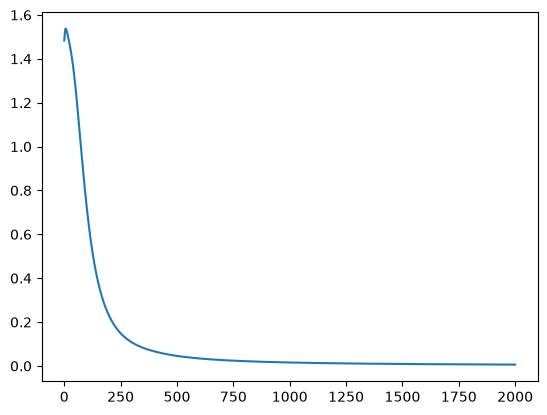

In [81]:
from matplotlib import pyplot as plt
plt.plot(np.arange(0, epohi + 1), bigerrors)

In [82]:
print(table)
showwesa()
print(aksonsall)

   id  class         y       err
0   0      0  0.039965 -0.039965
1   1      0  0.037869 -0.037869
2   2      1  0.982848  0.017152
3   3      1  0.964347  0.035653
4   4      0    0.0294   -0.0294
5   5      0  0.026792 -0.026792
-0.5391305072777943
-0.5740906432873587
0.48692698536307244
0.2750336479161273
-0.5116575106282704
0.08291839279388236
0.5026235481436077
0.3613874642084196
-0.9226637690018922
0.8249797539504726
0.5592620750239308
0.5406694708167237
-0.990444379103544
-0.01668434520669503
-0.5005908351541006
-0.23868221932369316
0.7078213972039014
-0.6016906000489921
-0.3164782256822538
-1.1121177678404441
-1.2708617060849996
-0.6861915466321716
-0.5960212860532419
-0.7976718373310152
-0.5377165968832873
0.01712429454150323
1.5906592076062305
-2.310304887219993
1.445572046053387
0.4762500519434367
0.23625370722776395
0.8234899165164924
-1.0220646903225963
-1.3213313332619605
-0.6500805559532343
0.7616673784427892
-0.6995723128125938
0.03854770178943889
-0.5726573742937542
-0

In [83]:
outputneiron.getvalue = getvaluePOROG
getBIGerror()
print(table)
showwesa()

   id  class  y err
0   0      0  0   0
1   1      0  0   0
2   2      1  1   0
3   3      1  1   0
4   4      0  0   0
5   5      0  0   0
-0.5391305072777943
-0.5740906432873587
0.48692698536307244
0.2750336479161273
-0.5116575106282704
0.08291839279388236
0.5026235481436077
0.3613874642084196
-0.9226637690018922
0.8249797539504726
0.5592620750239308
0.5406694708167237
-0.990444379103544
-0.01668434520669503
-0.5005908351541006
-0.23868221932369316
0.7078213972039014
-0.6016906000489921
-0.3164782256822538
-1.1121177678404441
-1.2708617060849996
-0.6861915466321716
-0.5960212860532419
-0.7976718373310152
-0.5377165968832873
0.01712429454150323
1.5906592076062305
-2.310304887219993
1.445572046053387
0.4762500519434367
0.23625370722776395
0.8234899165164924
-1.0220646903225963
-1.3213313332619605
-0.6500805559532343
0.7616673784427892
-0.6995723128125938
0.03854770178943889
-0.5726573742937542
-0.10664384392745681
-0.31011310277503185
0.3446925530170406
0.5043677797523574
0.89158782493

In [ ]:
%gui qt6

import sys
from PyQt6 import QtWidgets as qw

allbuttons = []
class krutayaknopka(qw.QPushButton):
    def __init__(self, text, myvalue, parent = ...):
        super().__init__()
        self.myvalue = myvalue
        self.activated = 1
        self.selectcolor()
        self.clicked.connect(self.selectcolor)
    def selectcolor(self):
        if self.activated == 0:
            self.activated = 1
            self.setStyleSheet("background-color: #FFFFFF")
        else:
            self.activated = 0
            self.setStyleSheet("background-color: #000000")
        self.delegat()
    def delegat(self):
        return

class krutoeokno(qw.QMainWindow):
    def __init__(self):
        super().__init__()
        razmer = 6

        layout = qw.QHBoxLayout()
        self.label = qw.QLabel("sadsadsad")
        layout.addWidget(self.label)
        grid = qw.QGridLayout()
        gridwidget = qw.QWidget()
        gridwidget.setFixedSize(50 * razmer, 50 * razmer)
        gridwidget.setLayout(grid)
        layout.addWidget(gridwidget)

        for row in range(razmer):
            for col in range(razmer):
                b = krutayaknopka("", row * razmer + col)
                b.setFixedSize(50, 50)
                allbuttons.append(b)
                grid.addWidget(b, row, col)
                
        
        self.setWindowTitle("акошко")
        self.setGeometry(100, 50, 500, 500)
        container = qw.QWidget()
        container.setLayout(layout)
        self.setCentralWidget(container)
        
window = krutoeokno()

def predictevent(kacherishka):
    X = [float(b.activated) for b in allbuttons]
    y = Test(X)
    if y == 0:
        window.label.setText("стоит")
    else:
        window.label.setText("идёт")
krutayaknopka.delegat = predictevent

window.show()